# 26 · A held-out test of stage 2 (chat-3), and C2 validated on it

**Purpose.** Plans `2026-10-21-chat3-holdout` and `2026-10-22-c2-validation`. Steps 3-5 of plan
`2026-10-18` trained stage 2 on `chat-1` and scored it on `chat-1`, on the 60 final-set JDs where
every choice was made. Here stage 2 is **chosen and trained on chat-3** (48 new train-region JDs the
owner scored) and **tested once** on the 60 final-set JDs, which nothing is fitted on (D62). Then the
zero-shot reranker C2 is chosen on chat-3 and tested once more (exploratory; D64 adopted it after).

**Decisions.** D62 (chat-3 trains, `chat-1` only tests), D63 (the system is L1 over the whole pool,
X2 the baseline), D64 (C2 reorders L1's top 50, adopted after the test missed its bar).

**Reading.** Recall@10 = the share of the chat's tie-aware top 10 in a system's top 10. Every figure
is a mean over JDs with a JD-bootstrapped 95% CI; deltas are paired by JD. Sections 4, 5 and 7 are
exploratory: the 60 JDs had already had their one test (section 3).

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from candidate_screener import reporting
from candidate_screener.config import OUTPUT

reporting.style(plt)
R = OUTPUT / "rerank"
load = lambda name: json.load(open(R / name))
pools, sel, test, vs_c2 = load("chat3-pools.json"), load("chat3-select.json"), load("chat3-test.json"), load("chat3-vs-c2.json")
cover, l1pool = load("chat3-stage1-coverage.json"), load("chat3-l1-pool.json")
c2sel, c2pool, c2test = load("c2-validation-select.json"), load("c2-validation-pool.json"), load("c2-validation-test.json")
fmt = lambda b: f"{b['value']:+.3f} [{b['ci'][0]:+.3f}, {b['ci'][1]:+.3f}]"
val = lambda b: f"{b['value']:.3f} [{b['ci'][0]:.3f}, {b['ci'][1]:.3f}]"
gt = lambda s: f"{s['generic']['value']:.3f} / {s['targeted']['value']:.3f}"

## 1 · chat-3: the training set

48 JDs from the A2 train region, never used before (not in the dev pools or D50), each with a
500-CV pool built like the final set's. X2's top 100 per JD was scored by the owner in claude.ai with
`chat-1`'s instrument. The guard row must be all zero: no JD or CV from the eval region, the final
set, the weak pairs, D50 or the dev pools.

In [2]:
j, p, c3 = pools["jds"], pools["pairs"], sel["chat_3"]
print("JDs:", j["total"], j["by_stratum"], "| targeted families:", j["targeted_by_family"])
print("pairs: pool", p["pool"], "| scored (X2 top 100)", p["shortlist"], "| batches", p["batches"])
print("forbidden overlap:", pools["forbidden_overlap"])
print("chat-3 labels:", c3["labels"], "| mean score", c3["mean_score"])

JDs: 48 {'generic': 32, 'targeted': 16} | targeted families: {'Business Analyst': 6, 'Data Analyst': 1, 'Data Engineer': 4, 'Data Science': 5}
pairs: pool 24000 | scored (X2 top 100) 4800 | batches 240
forbidden overlap: {'eval_region': 0, 'weak_pairs': 0, 'final_set': 0, 'd50_jds': 0, 'dev_pool_jds': 0}
chat-3 labels: {'Good Fit': 596, 'No Fit': 2761, 'Potential Fit': 1443} | mean score 28.397


## 2 · Stage 2 chosen on chat-3 (5-fold CV by JD)

The menu was fixed before chat-3 was scored: L1 (bounded ridge) or L2 (monotone boosting), on F12 or
F9. The highest out-of-fold Recall@10 wins; X2's order is context.

In [3]:
pd.DataFrame({n: {"R@10 [CI]": val(a["summary"]["recall"]["total"]), "generic / targeted": gt(a["summary"]["recall"]),
                  "nDCG@10": f"{a['summary']['ndcg']['total']['value']:.3f}"} for n, a in sel["arms"].items()}).T

,R@10 [CI],generic / targeted,nDCG@10
X2's order,"0.472 [0.412, 0.530]",0.414 / 0.588,0.794
L1 F9,"0.511 [0.450, 0.570]",0.468 / 0.599,0.815
L2 F9,"0.502 [0.441, 0.558]",0.465 / 0.574,0.809
L1 F12,"0.513 [0.450, 0.575]",0.468 / 0.605,0.818
L2 F12,"0.507 [0.445, 0.565]",0.477 / 0.568,0.809


In [4]:
print("winner:", sel["winner"])

winner: {'learner': 'L1', 'features': 'F12'}


## 3 · The held-out test (one run, rules fixed before scoring)

The winner, fitted once on all 4,800 chat-3 pairs, reranks X2's top 100 on the 60 final-set JDs.
Reference: `chat-1`. The old L2 (trained on `chat-1` out of fold) is shown for comparison only.

In [5]:
rows = {}
for n, r in test["results"].items():
    s = r["summary"]
    rows[n] = {"R@10 [CI]": val(s["recall"]["total"]), "generic / targeted": gt(s["recall"]),
               "Δ vs X2": fmt(r["delta_vs_X2"]["recall"]["total"]) if "delta_vs_X2" in r else "",
               "nDCG@10": f"{s['ndcg']['total']['value']:.3f}", "chat No Fits": f"{s['no_fits']['total']['value']:.2f}"}
pd.DataFrame(rows).T

,R@10 [CI],generic / targeted,Δ vs X2,nDCG@10,chat No Fits
X2,"0.419 [0.366, 0.471]",0.421 / 0.416,,0.776,1.70
X2 top 100 -> stage 2 (chat-3),"0.484 [0.442, 0.526]",0.497 / 0.459,"+0.065 [+0.036, +0.096]",0.822,1.35
X2 top 100 -> S1,"0.454 [0.403, 0.502]",0.464 / 0.432,"+0.034 [+0.005, +0.063]",0.801,1.55
"X2 top 100 -> L2 (chat-1, out of fold)","0.497 [0.452, 0.540]",0.503 / 0.485,"+0.078 [+0.046, +0.110]",0.826,1.30


In [6]:
for rule, r in test["rules"].items():
    print("PASS" if r["passes"] else "FAIL", "|", rule, "|", fmt(r["delta"]), "| n =", r["delta"]["n_jd"])

PASS | 1 headline: Recall@10 vs X2 >= +0.05, CI above 0 | +0.065 [+0.036, +0.096] | n = 60
PASS | 2 chat vs chat-free: Recall@10 vs S1's order > 0, CI above 0 | +0.031 [+0.007, +0.056] | n = 60
PASS | 3 humans: per-JD AUC (final label, all) vs X2 > 0, CI above 0 | +0.068 [+0.002, +0.143] | n = 48


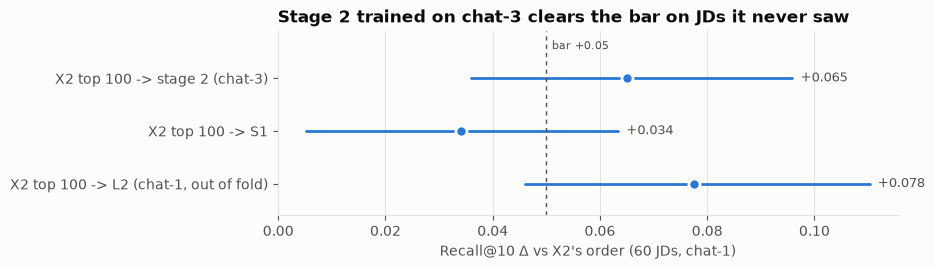

In [7]:
arms = [n for n in test["results"] if n != "X2"]
d = [test["results"][n]["delta_vs_X2"]["recall"]["total"] for n in arms]
fig, ax = plt.subplots(figsize=(8, 2.4))
reporting.dot_ci(ax, arms, [x["value"] for x in d], [x["ci"][0] for x in d], [x["ci"][1] for x in d],
                 ref=0.05, ref_label="bar +0.05", fmt="{:+.3f}")
ax.set_xlabel("Recall@10 Δ vs X2's order (60 JDs, chat-1)")
ax.set_title("Stage 2 trained on chat-3 clears the bar on JDs it never saw")
plt.show()

## 4 · Against the C2 results of steps 5b-5d (exploratory)

Same 60 JDs and `chat-1` reference, cached C2 scores, paired against stage 2 (chat-3). The last three
rows were trained on these JDs' chat scores and are not a clean comparison.

In [8]:
pd.DataFrame({n: {"R@10": f"{r['summary']['recall']['total']['value']:.3f}",
                  "Δ vs stage 2 (chat-3)": fmt(r["delta_vs_X2 top 100 -> stage 2 (chat-3)"]["recall"]["total"])
                  if "delta_vs_X2 top 100 -> stage 2 (chat-3)" in r else "–",
                  "nDCG@10": f"{r['summary']['ndcg']['total']['value']:.3f}"}
              for n, r in vs_c2["all_60"].items()}).T

,R@10,Δ vs stage 2 (chat-3),nDCG@10
X2,0.419,"-0.065 [-0.096, -0.036]",0.776
X2 top 100 -> C2,0.379,"-0.106 [-0.144, -0.067]",0.751
X2 top 100 -> S1,0.454,"-0.031 [-0.056, -0.007]",0.801
X2 top 100 -> C2 + S1,0.464,"-0.021 [-0.050, +0.009]",0.813
X2 top 100 -> stage 2 (chat-3),0.484,–,0.822
X2 top 100 -> C2 + stage 2 (chat-3),0.480,"-0.005 [-0.033, +0.025]",0.826
"X2 top 100 -> L2 (chat-1, out of fold)",0.497,"+0.012 [-0.011, +0.036]",0.826
X2 top 100 -> C2 + L2 (chat-1),0.501,"+0.016 [-0.009, +0.041]",0.840
L2 (chat-1) top 30 -> C2 + L2,0.522,"+0.037 [+0.013, +0.061]",0.849


## 5 · Stage-1 variants and the one-stage system (exploratory)

The share of the chat's top 10 inside each ranking's top k of the whole 500-CV pool (reference
`chat-1` + `chat-2`; unscored CVs count as misses). Then D63's check that L1 over the whole pool
returns the tested pipeline's top 10.

In [9]:
pd.DataFrame({n: {f"k={k}": f"{v['coverage']['total']['value']:.3f}" for k, v in by_k.items()}
              for n, by_k in cover["systems"].items()}).T

,k=10,k=20,k=30,k=50,k=100
X2 (500),0.417,0.632,0.744,0.838,0.964
S1 (500),0.448,0.668,0.763,0.847,0.944
L1 F12 chat-3 (500),0.475,0.683,0.774,0.860,0.960
X2 top 100 -> stage 2 (chat-3),0.475,0.689,0.770,0.862,0.964
"X2 top 100 -> L2 (chat-1, out of fold)",0.483,0.687,0.791,0.880,0.964


In [10]:
print("top 10 identical to the tested pipeline:", l1pool["a_top10_identical_to_tested_pipeline"])

top 10 identical to the tested pipeline: {'jds': 59, 'of': 60, 'tested_recall_at_10': 0.484413}


## 6 · C2 chosen on chat-3, tested once (plan 2026-10-22)

C2 (Qwen3-Reranker-0.6B, zero-shot) reorders L1's top k: `mm(L1) + w · mm(C2)` within the k. Nine
options, chosen by out-of-fold Recall@10 on chat-3 (2,400 C2 pairs). Gate: the winner must beat L1
alone on chat-3.

In [11]:
pd.DataFrame({n: {"R@10 [CI]": val(r["summary"]["recall"]["total"]), "generic / targeted": gt(r["summary"]["recall"]),
                  "Δ vs L1 alone": fmt(r["delta_vs_L1"]["recall"]["total"]) if "delta_vs_L1" in r else "–",
                  "nDCG@10": f"{r['summary']['ndcg']['total']['value']:.3f}"} for n, r in c2sel["options"].items()}).T

,R@10 [CI],generic / targeted,Δ vs L1 alone,nDCG@10
L1 alone,"0.513 [0.450, 0.575]",0.468 / 0.605,–,0.818
L1 top 20 -> L1 + 0.25 C2,"0.526 [0.462, 0.587]",0.474 / 0.630,"+0.013 [-0.000, +0.027]",0.828
L1 top 20 -> L1 + 0.5 C2,"0.518 [0.457, 0.576]",0.471 / 0.611,"+0.004 [-0.015, +0.023]",0.826
L1 top 20 -> L1 + 1.0 C2,"0.508 [0.450, 0.565]",0.451 / 0.621,"-0.005 [-0.034, +0.023]",0.825
L1 top 30 -> L1 + 0.25 C2,"0.531 [0.467, 0.592]",0.482 / 0.630,"+0.018 [+0.003, +0.033]",0.830
L1 top 30 -> L1 + 0.5 C2,"0.505 [0.446, 0.563]",0.456 / 0.605,"-0.008 [-0.029, +0.013]",0.826
L1 top 30 -> L1 + 1.0 C2,"0.504 [0.445, 0.562]",0.446 / 0.621,"-0.009 [-0.040, +0.022]",0.822
L1 top 50 -> L1 + 0.25 C2,"0.532 [0.468, 0.593]",0.483 / 0.630,"+0.019 [+0.003, +0.034]",0.830
L1 top 50 -> L1 + 0.5 C2,"0.503 [0.443, 0.562]",0.449 / 0.611,"-0.010 [-0.032, +0.013]",0.825
L1 top 50 -> L1 + 1.0 C2,"0.506 [0.448, 0.562]",0.451 / 0.615,"-0.008 [-0.040, +0.025]",0.821


In [12]:
print("winner:", c2sel["winner"]["name"], "| gate passes:", c2sel["gate"]["passes"])
print("chat-4 (pooled top-10 CVs without a chat score):", c2pool["chat_4"]["new_pairs"], "| unscored per option:", c2pool["unscored_in_top10"])

winner: L1 top 50 -> L1 + 0.25 C2 | gate passes: True
chat-4 (pooled top-10 CVs without a chat score): 0 | unscored per option: {'winner': 0, 'L1 alone': 0, 'X2': 0}


### The test (exploratory; 60 JDs, reference `chat-1` + `chat-2`)

Bar fixed before scoring: the winner's Recall@10 Δ vs L1 alone ≥ +0.02 with the CI above 0.

In [13]:
rows = {}
for n, r in c2test["results"].items():
    s = r["reference_A"]["summary"]
    rows[n] = {"R@10 [CI]": val(s["recall"]["total"]), "generic / targeted": gt(s["recall"]),
               "Δ R@10 vs L1": fmt(r["reference_A"]["delta_vs_L1"]["recall"]["total"]) if "delta_vs_L1" in r["reference_A"] else "–",
               "Δ nDCG@10 vs L1": fmt(r["reference_A"]["delta_vs_L1"]["ndcg"]["total"]) if "delta_vs_L1" in r["reference_A"] else "–",
               "chat No Fits": f"{s['no_fits']['total']['value']:.2f}", "R@10, chat-1 only": f"{r['reference_B_recall']['total']['value']:.3f}"}
print("bar met:", c2test["bar"]["met"], "|", fmt(c2test["bar"]["delta"]))
pd.DataFrame(rows).T

bar met: False | +0.005 [-0.010, +0.021]


,R@10 [CI],generic / targeted,Δ R@10 vs L1,Δ nDCG@10 vs L1,chat No Fits,"R@10, chat-1 only"
winner,"0.480 [0.436, 0.523]",0.487 / 0.467,"+0.005 [-0.010, +0.021]","+0.012 [+0.005, +0.019]",1.28,0.490
L1 alone,"0.475 [0.432, 0.517]",0.484 / 0.456,–,–,1.38,0.484
X2,"0.417 [0.366, 0.467]",0.419 / 0.414,"-0.058 [-0.088, -0.029]","-0.045 [-0.071, -0.023]",1.73,0.419


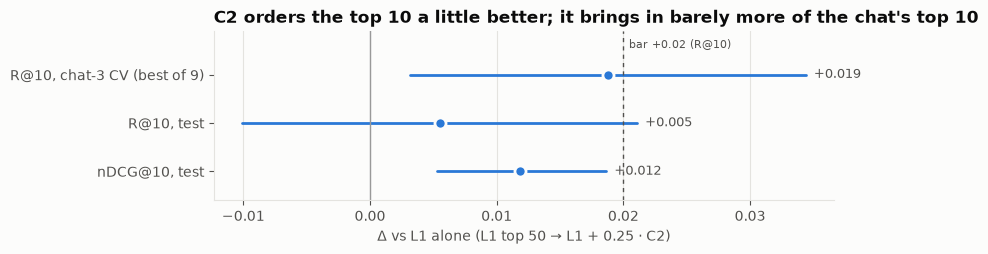

In [14]:
w = c2test["results"]["winner"]["reference_A"]["delta_vs_L1"]
cv = c2sel["options"][c2sel["winner"]["name"]]["delta_vs_L1"]
labels = ["R@10, chat-3 CV (best of 9)", "R@10, test", "nDCG@10, test"]
ds = [cv["recall"]["total"], w["recall"]["total"], w["ndcg"]["total"]]
fig, ax = plt.subplots(figsize=(8, 2.2))
reporting.dot_ci(ax, labels, [x["value"] for x in ds], [x["ci"][0] for x in ds], [x["ci"][1] for x in ds],
                 ref=0.02, ref_label="bar +0.02 (R@10)", fmt="{:+.3f}")
ax.axvline(0, color="0.6", linewidth=1)
ax.set_xlabel("Δ vs L1 alone (L1 top 50 → L1 + 0.25 · C2)")
ax.set_title("C2 orders the top 10 a little better; it brings in barely more of the chat's top 10")
plt.show()

In [15]:
h = c2test["human"]["systems"]["winner"]
for kind in ("auc", "pairwise"):
    for x in h[f"{kind}_delta_vs_L1 alone"]:
        if x["scope"] == "total":
            print(f"human {kind:8s} {x['subset']:8s} Δ vs L1 {x['delta']:+.3f} [{x['ci'][0]:+.3f}, {x['ci'][1]:+.3f}] n={x['n_jd']}")

human auc      all      Δ vs L1 -0.003 [-0.021, +0.013] n=48
human auc      llm_free Δ vs L1 -0.003 [-0.028, +0.019] n=36
human pairwise full     Δ vs L1 -0.006 [-0.018, +0.006] n=55
human pairwise llm_free Δ vs L1 -0.008 [-0.024, +0.006] n=52


## 7 · Findings

1. **Stage 2 trained on chat-3 passes all three rules on JDs it never saw.** L1 on F12 reaches
   Recall@10 0.484 against X2's 0.419: +0.065 [+0.036, +0.096], over the +0.05 bar; +0.031 over the
   chat-free S1 order; per-JD AUC on the human labels +0.068 [+0.002, +0.143] (narrowly; `llm_free`
   not above 0).
2. **Training and choosing on the reference was worth about 0.01.** The old L2 (trained on `chat-1`,
   chosen on these JDs) is +0.012 [−0.011, +0.036] above the clean stage 2, not significant.
3. **Stage 1 is not the bottleneck.** X2's top 100 holds 0.964 of the chat's top 10; L1 over the whole
   pool gives the same top 10 as X2 → L1 in 59 of 60 JDs and the same Recall@10 (D63).
4. **C2 adds order, not recall.** Chosen on chat-3 (+0.019, the best of nine), L1 top 50 → L1 + 0.25 ·
   C2 adds +0.005 [−0.010, +0.021] Recall@10 on the test (bar +0.02 **not met**) and +0.012 [+0.005,
   +0.019] nDCG@10, with 0.1 fewer chat No Fits; the human check does not move. The owner adopted it
   after the test (D64), post hoc. Larger C2 weights never helped.
5. **The reference was complete where it mattered.** Every CV in the compared top 10s already had a
   `chat-1` or `chat-2` score, so chat-4 was empty.

## Limitations

- One judge (Claude Haiku) behind chat-1, chat-2 and chat-3; it reproduces about 0.80 of its own top
  10 on a retest. The human labels cover ~7 CVs per JD inside X2's top 100.
- The chat-3 pools were not banded by experience, unlike the final set's labelled picks; the
  `chat-1`-trained L2 still leads on the human check (+0.05 AUC), cause untested.
- Sections 4-6 reuse the 60 JDs after section 3; D64 overrides a registered bar.